# 3.02 — Modelo Poisson: preprocesamiento, ajuste de hiperparámetros y evaluación

**Proyecto:** MiBici · TC5044.10 · Equipo 04
**Autor:** José Eduardo De Moraes López
**Modelo:** `PoissonRegressor` (bloque `poisson` de `mibici/modeling/models.py`)
**Rama:** `feat/phase2-poisson`
**Fecha:** 7 de noviembre de 2026



## 1. Objetivo y justificación del algoritmo

1. Entrenar un `PoissonRegressor` con el pipeline común y compararlo con el baseline del contrato (promedio de 4 semanas: **WAPE 0.696**).
2. Elegir el **preprocesamiento** adecuado para un modelo lineal en escala logarítmica.
3. Ajustar el hiperparámetro de regularización `alpha`.
4. Verificar la estabilidad de la mejor configuración en las ventanas de junio y julio.
5. Dejar la configuración final en `models.py` para que `make train MODEL=poisson` la reproduzca y quede registrada en MLflow.

**¿Por qué Poisson?**

| Característica del problema | Cómo la atiende `PoissonRegressor` |
|---|---|
| El target `departures` es un **conteo** no negativo (≈43 % de ceros) | Modela $y \sim \text{Poisson}(\mu)$ con pérdida *deviance* de Poisson, la adecuada para conteos |
| La demanda es **multiplicativa** (una estación grande escala todo su perfil horario) | Enlace logarítmico: $\log \mu = w^\top x + b$, cada coeficiente es un factor $e^{w}$ |
| Se necesita una **referencia interpretable** y rápida | Es un modelo lineal generalizado (GLM): pocos parámetros, coeficientes legibles y entrenamiento de minutos |
| Hay que superar al promedio de 4 semanas | Con $\log(1+\text{avg\_4\_weeks})$ como entrada, el modelo puede reescalar ese promedio y corregirlo con el calendario |

Su limitación es que es **lineal en la escala log**: no aprende por sí solo interacciones (p. ej., que el pico de las 8:00 solo existe entre semana). Por eso el preprocesamiento es la parte central de esta libreta; los modelos de árboles del equipo (3.03 y 3.04) aprenden esas interacciones solos.

## 2. Configuración

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.exceptions import ConvergenceWarning
from sklearn.preprocessing import StandardScaler

from mibici.config import FEATURES, FIGURES_DIR, RANDOM_STATE, TARGET
from mibici.modeling.metrics import evaluate
from mibici.modeling.models import MODELS, make_model, poisson_preprocessing
from mibici.modeling.splits import split_summary, train_eval_masks
from mibici.modeling.train import load_modeling_table

pd.set_option("display.float_format", "{:.4f}".format)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Parámetros de la exploración (no son parte del contrato)
MAX_ITER = 1000                           # iteraciones de lbfgs; el default (100) no converge
EXPLORATION_ALPHA = 1e-4                  # alpha fija mientras se compara el preprocesamiento
ALPHAS = [1e-6, 1e-4, 1e-2]               # rejilla de regularización (sección 6)
OFFSETS = [0.01, 0.05, 0.1, 0.3, 1.0]     # rejilla del offset de log(x + offset) (sección 6)

2026-11-07 00:39:42.058 | INFO     | mibici.config:<module>:12 - PROJ_ROOT path is: C:\Users\lalo4\MiBici


## 3. Datos y partición del contrato

`load_modeling_table()` lee `processed_v1` y agrega las variables de historia (`avg_4_weeks`, `t_168`). `train_eval_masks(data, "validation")` devuelve las filas de entrenamiento (2022-01-01 → 2026-05-31) y las evaluadas (2026-06-01 → 2026-07-31).

In [2]:
start = time.perf_counter()
data = load_modeling_table()
train, evaluated = train_eval_masks(data, "validation")
X_train, y_train = data[train], data.loc[train, TARGET]
X_eval = data[evaluated]
print(f"{len(data):,} filas · train {train.sum():,} · validation {evaluated.sum():,} "
      f"· {time.perf_counter() - start:.0f} s")
print("Features del contrato:", FEATURES)
split_summary(data)

11,949,160 filas · train 10,827,060 · validation 511,960 · 14 s
Features del contrato: ['hour', 'day_of_week', 'is_weekend', 'month', 'station_age_days', 'avg_4_weeks', 't_168']


,start,end,rows,stations,zero_share,new_cohort_stations,rows_unseen_in_train,rows_without_history
period,,,,,,,,
train,2022-01-01,2026-05-31 23:00:00,10869060,385,0.4228,12,0.0000,42000
validation,2026-06-01,2026-07-31 23:00:00,511960,454,0.4874,86,0.0945,0
test,2026-08-01,2026-09-30 23:00:00,568140,469,0.4746,98,0.1809,0
window_june,2026-06-01,2026-06-30 23:00:00,240200,427,0.4855,59,0.0508,0
window_july,2026-07-01,2026-07-31 23:00:00,271760,453,0.4889,85,0.1331,0


Las variables de historia y la antigüedad tienen colas largas (muchos valores pequeños y pocos muy grandes). Para un modelo con enlace log conviene transformarlas con $\log(1+x)$:

In [3]:
data.loc[train, ["avg_4_weeks", "t_168", "station_age_days", TARGET]].describe(
    percentiles=[0.5, 0.9, 0.99]
).T

,count,mean,std,min,50%,90%,99%,max
avg_4_weeks,10827060.0000,1.7226,2.3620,0.0000,1.0000,4.2500,11.0000,77.0000
t_168,10827060.0000,1.7245,2.6732,0.0000,1.0000,5.0000,12.0000,205.0000
station_age_days,10827060.0000,2457.1392,1071.8002,0.0000,2688.0000,3664.0000,4133.0000,4199.0000
departures,10827060.0000,1.7253,2.6746,0.0000,1.0000,5.0000,12.0000,205.0000


## 4. Referencia: baseline del contrato

Todas las corridas se comparan con el baseline sobre **las mismas filas**. Funciones auxiliares de la libreta: `fit_and_score` entrena un pipeline común y devuelve la tabla de `evaluate` (MAE y WAPE por segmento) más el tiempo y si hubo aviso de no convergencia.

In [4]:
def fit_and_score(model, X_fit, y_fit, X_score):
    # Entrena el pipeline y lo evalúa por segmento con la métrica común del contrato
    start = time.perf_counter()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(X_fit, y_fit)
    seconds = time.perf_counter() - start
    converged = not any(issubclass(w.category, ConvergenceWarning) for w in caught)
    return model, evaluate(X_score, model.predict(X_score)), seconds, converged


def summary_row(name, scores, seconds=np.nan, converged=True):
    # Una fila resumen: WAPE/MAE de todas las filas y WAPE por segmento
    row = {"config": name, "wape": scores.loc["all", "wape"], "mae": scores.loc["all", "mae"]}
    row |= {f"wape_{seg}": scores.loc[seg, "wape"] for seg in scores.index if seg != "all"}
    return row | {"fit_seconds": round(seconds, 1), "converged": converged}


baseline, baseline_scores, _, _ = fit_and_score(make_model("baseline"), X_train, y_train, X_eval)
BASELINE_WAPE = baseline_scores.loc["all", "wape"]
baseline_scores

,rows,departures,mae,wape
segment,,,,
all,511960,710943,0.9670,0.6964
established_stations,448960,680189,1.0271,0.6779
new_station_cohort,63000,30754,0.5388,1.1037


## 5. Preprocesamiento: de los valores crudos a un GLM bien especificado

Se comparan cinco variantes con `alpha` fija. Todas usan el pipeline común (`make_model("poisson")`), cambiando solo el paso `preprocess`:

| Variante | Preprocesamiento | Hipótesis |
|---|---|---|
| A · default | Ninguno (valores crudos), `max_iter=100` de scikit-learn | Punto de partida: una pendiente por variable cruda |
| B · escalado | `StandardScaler` a las 7 variables | Converge, pero la hora entra como recta: no hay picos |
| C · one-hot | Calendario en one-hot + $\log(1+x)$ en historia y antigüedad | Un coeficiente por hora, día y mes; demanda proporcional a la historia |
| D · hora × tipo de día | C + interacción hora × (entre semana / fin de semana) | El perfil horario cambia el fin de semana |
| E · hora × día | C + interacción hora × día de la semana | Perfil horario propio de cada día (más parámetros) |
| F · D sin log | D, con historia solo estandarizada | Verifica que la transformación log aporta |

`poisson_preprocessing()` vive en `mibici/modeling/models.py`, así la libreta y `make train` usan exactamente el mismo código.

In [5]:
variants = {
    "A_default": (None, {"model__regressor__max_iter": 100}),
    "B_scaled": (StandardScaler(), {}),
    "C_onehot_log": (poisson_preprocessing(interaction=None, history_offset=1.0), {}),
    "D_hour_x_daytype": (poisson_preprocessing(interaction="day_type", history_offset=1.0), {}),
    "E_hour_x_weekday": (poisson_preprocessing(interaction="weekday", history_offset=1.0), {}),
    "F_daytype_no_log": (poisson_preprocessing(interaction="day_type", history_offset=None), {}),
}

rows = [summary_row("baseline", baseline_scores)]
for name, (prep, extra) in variants.items():
    params = {
        "preprocess": prep if prep is not None else "passthrough",
        "model__regressor__alpha": EXPLORATION_ALPHA,
        "model__regressor__max_iter": MAX_ITER,
    } | extra  # la variante A sobrescribe max_iter con el default de scikit-learn
    model = make_model("poisson").set_params(**params)
    _, scores, seconds, converged = fit_and_score(model, X_train, y_train, X_eval)
    rows.append(summary_row(name, scores, seconds, converged))
    print(f"{name:<18} WAPE {scores.loc['all', 'wape']:.4f} · {seconds:5.0f} s · converge={converged}")

preprocessing_results = pd.DataFrame(rows).set_index("config")
preprocessing_results

A_default          WAPE 1.1917 ·     3 s · converge=True


B_scaled           WAPE 0.9928 ·    27 s · converge=True


C_onehot_log       WAPE 0.7197 ·    16 s · converge=True


D_hour_x_daytype   WAPE 0.7183 ·    16 s · converge=True


E_hour_x_weekday   WAPE 0.7182 ·   100 s · converge=True


F_daytype_no_log   WAPE 0.8848 ·   146 s · converge=True


,wape,mae,wape_established_stations,wape_new_station_cohort,fit_seconds,converged
config,,,,,,
baseline,0.6964,0.9670,0.6779,1.1037,NaN,True
A_default,1.1917,1.6548,1.1055,3.0967,3.1000,True
B_scaled,0.9928,1.3787,0.9618,1.6800,27.3000,True
C_onehot_log,0.7197,0.9994,0.6990,1.1771,15.7000,True
D_hour_x_daytype,0.7183,0.9975,0.6977,1.1729,16.3000,True
E_hour_x_weekday,0.7182,0.9973,0.6976,1.1725,100.2000,True
F_daytype_no_log,0.8848,1.2287,0.8720,1.1678,146.2000,True


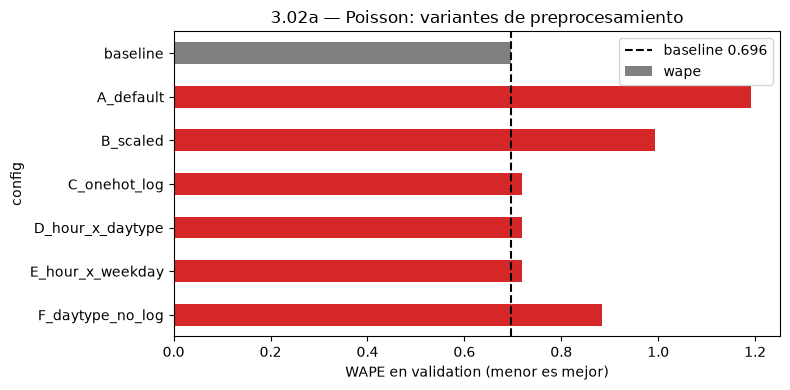

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
results = preprocessing_results["wape"]
colors = ["grey" if name == "baseline" else ("tab:green" if w < BASELINE_WAPE else "tab:red")
          for name, w in results.items()]
results.plot.barh(ax=ax, color=colors)
ax.axvline(BASELINE_WAPE, color="black", linestyle="--", label=f"baseline {BASELINE_WAPE:.3f}")
ax.set_xlabel("WAPE en validation (menor es mejor)")
ax.set_title("3.02a — Poisson: variantes de preprocesamiento")
ax.invert_yaxis()
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "3.02a-poisson-preprocessing.png", dpi=150)
plt.show()

**Resultados de la sección 5.**

- **A y B** (variables crudas o solo escaladas) quedan muy por encima del baseline, con WAPE de 1.19 y 0.99. Una sola pendiente para `hour`, `month` o `avg_4_weeks` no representa los picos de las 8:00 y las 18:00 ni la escala de cada estación.
- **El cambio más importante es la transformación log de la historia.** La misma variante da 0.885 con la historia solo estandarizada (F) y 0.718 con log (D). Con enlace log, tener $\log(x)$ como entrada hace que el pronóstico sea proporcional a la historia de la estación, que es la forma real de la demanda.
- **El one-hot del calendario** (C, 0.720) es lo que permite un perfil horario realista. Las interacciones aportan poco (D 0.7183, E 0.7182), porque `avg_4_weeks` ya es *de la misma estación, día y hora* y por eso ya trae el perfil horario de cada día.
- Todas las variantes convergen con `max_iter=1000` en menos de 35 s sobre 10.8 M filas.
- Ninguna variante con offset = 1 (`log1p`) supera al baseline (0.696). La sección 6 explora el offset.

## 6. Ajuste de hiperparámetros: `alpha` y offset de la historia

Se ajustan dos hiperparámetros sobre la interacción ganadora de la sección 5:

- **`alpha`** (`model__regressor__alpha`): penalización L2 de los coeficientes. Con ≈10.8 M filas se espera que baste una penalización pequeña; una grande encoge el calendario hacia cero y aplana el perfil horario.
- **offset** (`preprocess__history__log__offset`): la historia entra como $\log(x+\text{offset})$. Con offset = 1 (`log1p`), historias de 0.1 y 0.5 quedan casi iguales ($\log 1.1 \approx 0.10$ vs $\log 1.5 \approx 0.41$); con un offset pequeño el pronóstico se vuelve casi **proporcional** a la historia, como el baseline. ≈43 % de las filas son ceros y la mediana de `avg_4_weeks` es baja, así que esta zona pesa mucho.

Rejilla completa `OFFSETS × ALPHAS`, todas en validation.

In [7]:
candidates = preprocessing_results.drop(index="baseline")
interaction_of = {"C_onehot_log": None, "D_hour_x_daytype": "day_type", "E_hour_x_weekday": "weekday"}
log_variants = candidates.loc[list(interaction_of)]          # solo variantes con log en la historia
BEST_INTERACTION = interaction_of[log_variants["wape"].idxmin()]
print("Mejor variante con log:", log_variants["wape"].idxmin(), "→ interacción", BEST_INTERACTION)

rows = []
for offset in OFFSETS:
    for alpha in ALPHAS:
        model = make_model("poisson").set_params(
            preprocess=poisson_preprocessing(interaction=BEST_INTERACTION, history_offset=offset),
            model__regressor__alpha=alpha, model__regressor__max_iter=MAX_ITER,
        )
        _, scores, seconds, converged = fit_and_score(model, X_train, y_train, X_eval)
        rows.append(summary_row(f"offset={offset:g}, alpha={alpha:g}", scores, seconds, converged)
                    | {"offset": offset, "alpha": alpha})
        print(f"offset={offset:<5g} alpha={alpha:<6g} WAPE {scores.loc['all', 'wape']:.4f} · {seconds:4.0f} s")

grid_results = pd.DataFrame(rows).set_index("config")
best = grid_results.loc[grid_results["wape"].idxmin()]
BEST_OFFSET, BEST_ALPHA = float(best["offset"]), float(best["alpha"])
print(f"Mejor: offset={BEST_OFFSET:g}, alpha={BEST_ALPHA:g}, WAPE {best['wape']:.4f} "
      f"(baseline {BASELINE_WAPE:.4f})")
grid_results.sort_values("wape").head(8)

Mejor variante con log: E_hour_x_weekday → interacción weekday


offset=0.01  alpha=1e-06  WAPE 0.7106 ·   72 s


offset=0.01  alpha=0.0001 WAPE 0.7106 ·   81 s


offset=0.01  alpha=0.01   WAPE 0.7146 ·   50 s


offset=0.05  alpha=1e-06  WAPE 0.7047 ·   94 s


offset=0.05  alpha=0.0001 WAPE 0.7047 ·   79 s


... (7 outputs left out)

offset=1     alpha=1e-06  WAPE 0.7181 ·   98 s


offset=1     alpha=0.0001 WAPE 0.7182 ·  107 s


offset=1     alpha=0.01   WAPE 0.7222 ·   62 s
Mejor: offset=0.1, alpha=1e-06, WAPE 0.7039 (baseline 0.6964)


,wape,mae,wape_established_stations,wape_new_station_cohort,fit_seconds,converged,offset,alpha
config,,,,,,,,
"offset=0.1, alpha=1e-06",0.7039,0.9775,0.6866,1.0866,98.2000,True,0.1000,0.0000
"offset=0.1, alpha=0.0001",0.7040,0.9777,0.6867,1.0869,100.6000,True,0.1000,0.0001
"offset=0.05, alpha=1e-06",0.7047,0.9786,0.6882,1.0700,93.9000,True,0.0500,0.0000
"offset=0.05, alpha=0.0001",0.7047,0.9786,0.6882,1.0704,78.8000,True,0.0500,0.0001
"offset=0.1, alpha=0.01",0.7063,0.9808,0.6888,1.0938,50.6000,True,0.1000,0.0100
"offset=0.3, alpha=1e-06",0.7065,0.9811,0.6876,1.1236,105.4000,True,0.3000,0.0000
"offset=0.3, alpha=0.0001",0.7065,0.9811,0.6876,1.1237,104.4000,True,0.3000,0.0001
"offset=0.05, alpha=0.01",0.7073,0.9822,0.6906,1.0766,55.1000,True,0.0500,0.0100


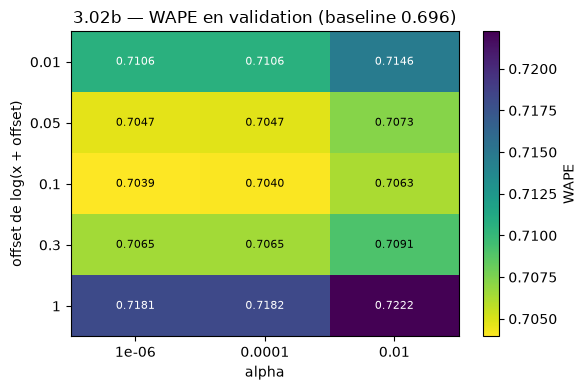

In [8]:
heat = grid_results.pivot(index="offset", columns="alpha", values="wape")
fig, ax = plt.subplots(figsize=(6, 4))
im = ax.imshow(heat.values, cmap="viridis_r", aspect="auto")
ax.set_xticks(range(len(heat.columns)), [f"{a:g}" for a in heat.columns])
ax.set_yticks(range(len(heat.index)), [f"{o:g}" for o in heat.index])
for (r, c), value in np.ndenumerate(heat.values):
    ax.text(c, r, f"{value:.4f}", ha="center", va="center", fontsize=8,
            color="white" if value > np.nanmean(heat.values) else "black")
ax.set_xlabel("alpha")
ax.set_ylabel("offset de log(x + offset)")
ax.set_title(f"3.02b — WAPE en validation (baseline {BASELINE_WAPE:.3f})")
fig.colorbar(im, ax=ax, label="WAPE")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "3.02b-poisson-grid.png", dpi=150)
plt.show()

**Resultados de la sección 6.**

- **El offset es el hiperparámetro que más importa.** Pasar de offset = 1 (0.718) a offset = 0.1 (0.704) reduce el WAPE ≈ 2 %. Un offset más chico (0.01) vuelve a empeorar el resultado (0.711), porque da demasiado peso a la diferencia entre historias de 0 y de 0.25, que es casi ruido.
- **`alpha` casi no influye** mientras sea pequeña: 1e-6 y 1e-4 dan prácticamente lo mismo, y 1e-2 ya empeora en todas las filas. Con 10.8 M filas y 183 coeficientes no hay sobreajuste que regularizar.
- La mejor configuración (hora × día, offset = 0.1, alpha = 1e-6) logra **WAPE 0.7039**, todavía **≈1 % peor que el baseline** (0.6964).

## 7. Configuración final en `models.py`

La mejor combinación se copió al bloque `poisson` de `mibici/modeling/models.py`, junto con la rejilla de la sección 6 que se usará en `make train MODEL=poisson` (una corrida de MLflow por combinación). La siguiente celda verifica que el bloque coincide con lo elegido aquí, para que la libreta y el entrenamiento oficial no se desincronicen.

In [9]:
block = MODELS["poisson"]
final_model = make_model("poisson")
params = final_model.get_params()
print("Estimador:", block["estimator"])
print("Rejilla:", block["param_grid"])

assert params["model__regressor__alpha"] == BEST_ALPHA, "Copia BEST_ALPHA al bloque poisson"
assert params["model__regressor__max_iter"] == MAX_ITER
assert params["preprocess__history__log__offset"] == BEST_OFFSET, "Copia BEST_OFFSET al bloque"
names = [name for name, _, _ in final_model.named_steps["preprocess"].transformers]
expected = "hour_x_" + BEST_INTERACTION if BEST_INTERACTION else None
assert expected is None or expected in names, "La interacción del bloque no es BEST_INTERACTION"
assert set(block["param_grid"]) <= {"model__regressor__alpha", "preprocess__history__log__offset"}
print("El bloque poisson de models.py coincide con la mejor configuración.")

Estimador: PoissonRegressor(alpha=1e-06, max_iter=1000)
Rejilla: {'preprocess__history__log__offset': [0.01, 0.05, 0.1, 0.3, 1.0], 'model__regressor__alpha': [1e-06, 0.0001, 0.01]}
El bloque poisson de models.py coincide con la mejor configuración.


## 8. Evaluación de la configuración final

### 8.1 Validation por segmento y estabilidad en las ventanas

Regla del contrato (3.01, sección 7.6): un modelo es **candidato** solo si supera al baseline en WAPE en validation **y** en las dos ventanas (`window_june` entrena hasta mayo y evalúa junio; `window_july` entrena hasta junio y evalúa julio).

In [10]:
final_model, final_scores, final_seconds, _ = fit_and_score(
    make_model("poisson"), X_train, y_train, X_eval
)
comparison = pd.concat({"poisson": final_scores, "baseline": baseline_scores}, names=["source"])
comparison

rows  departures    mae   wape
source   segment                                               
poisson  all                   511960      710943 0.9775 0.7039
         established_stations  448960      680189 1.0403 0.6866
         new_station_cohort     63000       30754 0.5304 1.0866
baseline all                   511960      710943 0.9670 0.6964
         established_stations  448960      680189 1.0271 0.6779
         new_station_cohort     63000       30754 0.5388 1.1037

In [11]:
rows = []
for mode in ["validation", "window_june", "window_july"]:
    fit_rows, score_rows = train_eval_masks(data, mode)
    X_fit, y_fit, X_score = data[fit_rows], data.loc[fit_rows, TARGET], data[score_rows]
    if mode == "validation":
        scores, base = final_scores, baseline_scores
    else:
        _, scores, _, _ = fit_and_score(make_model("poisson"), X_fit, y_fit, X_score)
        _, base, _, _ = fit_and_score(make_model("baseline"), X_fit, y_fit, X_score)
    rows.append({
        "mode": mode,
        "poisson_wape": scores.loc["all", "wape"],
        "baseline_wape": base.loc["all", "wape"],
        "poisson_mae": scores.loc["all", "mae"],
        "baseline_mae": base.loc["all", "mae"],
    })

stability = pd.DataFrame(rows).set_index("mode")
stability["wape_improvement_%"] = 100 * (1 - stability["poisson_wape"] / stability["baseline_wape"])
stability["beats_baseline"] = stability["poisson_wape"] < stability["baseline_wape"]
IS_CANDIDATE = bool(stability["beats_baseline"].all())
print("¿Candidato según el contrato?", IS_CANDIDATE)
stability

¿Candidato según el contrato? False


,poisson_wape,baseline_wape,poisson_mae,baseline_mae,wape_improvement_%,beats_baseline
mode,,,,,,
validation,0.7039,0.6964,0.9775,0.9670,-1.0895,False
window_june,0.7317,0.7227,1.0317,1.0191,-1.2436,False
window_july,0.6792,0.6724,0.9303,0.9210,-1.0069,False


### 8.2 ¿Dónde gana y dónde pierde? Error por hora del día

El WAPE global puede esconder diferencias: se calcula por hora de servicio sobre validation.

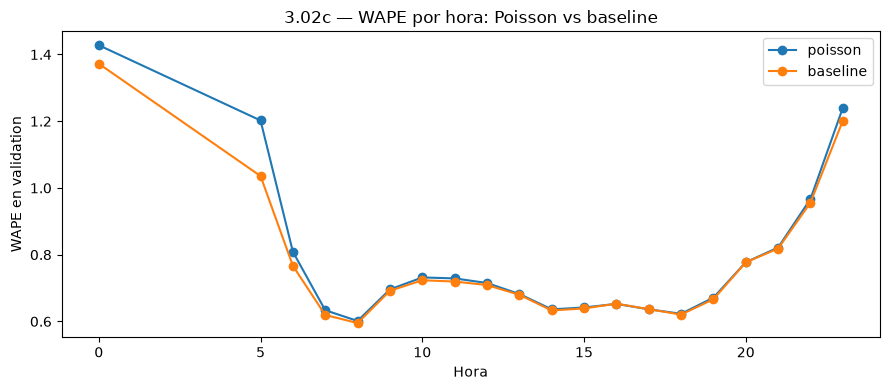

hour,0,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
poisson,1.4278,1.2023,0.8087,0.6335,0.6014,0.6960,0.7318,0.7289,0.7152,0.6822,0.6362,0.6417,0.6526,0.6363,0.6229,0.6711,0.7773,0.8214,0.9667,1.2398
baseline,1.3723,1.0357,0.7667,0.6193,0.5951,0.6919,0.7234,0.7196,0.7090,0.6799,0.6329,0.6389,0.6532,0.6367,0.6205,0.6665,0.7771,0.8184,0.9561,1.2016


In [12]:
def wape_by(rows, y_pred, column):
    # WAPE de cada valor de `column`: suma de errores absolutos / suma de salidas
    frame = pd.DataFrame({column: rows[column].to_numpy(), "y": rows[TARGET].to_numpy(),
                          "abs_err": np.abs(rows[TARGET].to_numpy() - y_pred)})
    grouped = frame.groupby(column)[["abs_err", "y"]].sum()
    return grouped["abs_err"] / grouped["y"]


poisson_pred = final_model.predict(X_eval)
baseline_pred = baseline.predict(X_eval)
by_hour = pd.DataFrame({
    "poisson": wape_by(X_eval, poisson_pred, "hour"),
    "baseline": wape_by(X_eval, baseline_pred, "hour"),
})

fig, ax = plt.subplots(figsize=(9, 4))
by_hour.plot(ax=ax, marker="o")
ax.set_xlabel("Hora")
ax.set_ylabel("WAPE en validation")
ax.set_title("3.02c — WAPE por hora: Poisson vs baseline")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "3.02c-poisson-wape-by-hour.png", dpi=150)
plt.show()
by_hour.T

### 8.3 Interpretación: efectos multiplicativos

Con enlace log, $e^{w}$ es el factor por el que se multiplica la demanda esperada. Se muestran los coeficientes de la historia y la antigüedad, y el ajuste de la interacción hora × día elegida.

Intercepto: 0.053 · 183 coeficientes

Factor e^w por +1 desviación estándar de la variable transformada (log):
history__avg_4_weeks    2.9620
history__t_168          1.0620
age__station_age_days   1.0740


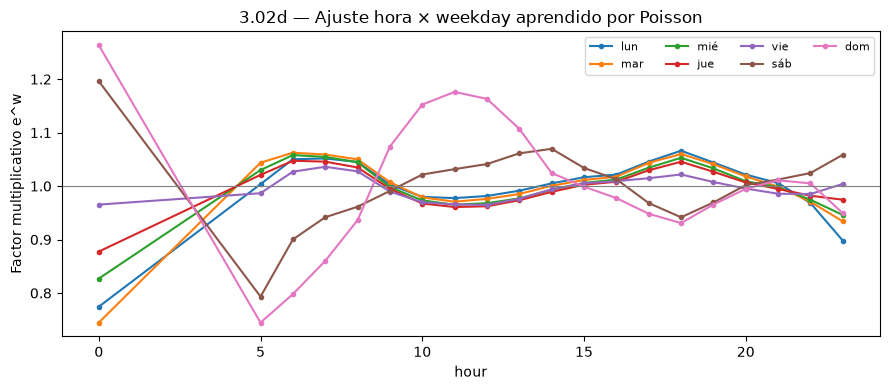

In [13]:
prep = final_model.named_steps["preprocess"]
regressor = final_model.named_steps["model"].regressor_
coefs = pd.Series(regressor.coef_, index=prep.get_feature_names_out())
print(f"Intercepto: {regressor.intercept_:.3f} · {len(coefs)} coeficientes")
print("\nFactor e^w por +1 desviación estándar de la variable transformada (log):")
print(np.exp(coefs.filter(regex="^(history|age)__")).round(3).to_string())

# Ajuste hora × día aprendido por la interacción (además de los efectos de hora y día)
DAY_NAMES = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]  # day_of_week: 0 = lunes
interaction = coefs.filter(regex="^hour_x_")
if len(interaction):
    codes = interaction.index.str.rsplit("_", n=1).str[-1].astype(int)
    if BEST_INTERACTION == "weekday":
        hours, groups, labels = codes // 10, codes % 10, DAY_NAMES
    else:
        hours, groups, labels = codes // 2, codes % 2, ["entre semana", "fin de semana"]
    profile = pd.DataFrame({"hour": hours, "group": groups, "factor": np.exp(interaction.values)})
    profile = profile.pivot(index="hour", columns="group", values="factor")
    profile.columns = [labels[g] for g in profile.columns]
    fig, ax = plt.subplots(figsize=(9, 4))
    profile.plot(ax=ax, marker=".")
    ax.axhline(1, color="grey", linewidth=0.8)
    ax.set_ylabel("Factor multiplicativo e^w")
    ax.set_title(f"3.02d — Ajuste hora × {BEST_INTERACTION} aprendido por Poisson")
    ax.legend(ncol=4, fontsize=8)
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / "3.02d-poisson-hour-interaction.png", dpi=150)
    plt.show()

### 8.4 Diagnóstico: pronóstico de la media contra la mediana

El WAPE suma errores **absolutos**. En una distribución de conteos sesgada (≈49 % de ceros en validation), el pronóstico que minimiza el error absoluto es la **mediana**, que queda por debajo de la media. Poisson estima la **media** condicional y está bien calibrado: la suma de sus pronósticos es casi igual a la suma real. La celda siguiente **solo diagnostica** esta hipótesis multiplicando los pronósticos por un factor fijo. El factor no se usa para elegir nada ni se aplica al modelo, porque cambiaría el contrato y estaría elegido en validation.

In [14]:
print(f"Suma pronosticada / suma real (validation): {poisson_pred.sum() / X_eval[TARGET].sum():.3f}")
diagnostic = pd.DataFrame({
    factor: {"poisson": evaluate(X_eval, factor * poisson_pred).loc["all", "wape"],
             "baseline": evaluate(X_eval, factor * baseline_pred).loc["all", "wape"]}
    for factor in [0.7, 0.8, 0.9, 1.0]
}).T.rename_axis("factor")
diagnostic

Suma pronosticada / suma real (validation): 0.989


,poisson,baseline
factor,,
0.7000,0.7021,0.6860
0.8000,0.6923,0.6777
0.9000,0.6930,0.6825
1.0000,0.7039,0.6964


## 9. Entrenamiento oficial con MLflow

Con el bloque actualizado y **con commit** (si no, la corrida queda con `git_dirty=true`), en Anaconda Prompt desde la raíz del repo y con `conda activate mibici`:

```bat
:: terminal 1 — servidor de MLflow (déjala abierta)
mlflow server --backend-store-uri sqlite:///mlflow/backend/mlflow.db --default-artifact-root mlflow/artifacts --host 127.0.0.1 --port 5000

:: terminal 2 — una corrida por valor de alpha de la rejilla, luego las ventanas
python -m mibici.modeling.train --model poisson --mode validation
python -m mibici.modeling.train --model poisson --mode window_june
python -m mibici.modeling.train --model poisson --mode window_july
```

(Equivale a `make mlflow` y `make train MODEL=poisson MODE=...` en Git Bash/Linux.) En `http://127.0.0.1:5000` → experimento `mibici-modeling` se comparan las corridas `poisson-*` contra las métricas `baseline_*` registradas en la misma corrida. Capturas en `reports/evidence/f2_poisson/`.

`train.py` corre toda la rejilla del bloque en cada modo (cada corrida tarda segundos), así que en las ventanas también aparecen las demás combinaciones: para la regla de candidato cuenta la de `BEST_OFFSET` y `BEST_ALPHA`, identificable en MLflow por los parámetros `preprocess__history__log__offset` y `model__regressor__alpha`.

## 10. Conclusiones y áreas de mejora

**Resultados**

| Modo | Poisson WAPE | Baseline WAPE | Diferencia |
|---|---|---|---|
| validation | 0.7039 | 0.6964 | +1.1 % |
| window_june | 0.7317 | 0.7227 | +1.2 % |
| window_july | 0.6792 | 0.6724 | +1.0 % |

1. **El modelo Poisson no es candidato** según la regla del contrato, porque queda ≈1 % por encima del baseline en validation y en las dos ventanas. El resultado es **estable**: la diferencia es casi igual en junio y en julio, y el modelo sigue la misma curva por hora que el baseline (figura 3.02c). No pierde por ser inestable. Pierde porque el baseline ya es la historia propia de cada estación, día y hora, y Poisson solo puede reescalarla con una función global y suave (punto 4).
2. **Sí mejora en la cohorte de estaciones nuevas 2026**, con WAPE 1.087 contra 1.104 del baseline y menor MAE. Para estaciones sin historia propia, el calendario y la antigüedad aportan información que el promedio de 4 semanas no tiene.
3. **Lo que más aportó fue el preprocesamiento, no el ajuste del estimador.** La transformación $\log(x+0.1)$ de la historia bajó el WAPE de 0.885 a 0.704, y el one-hot del calendario lo bajó de 0.993 a 0.720. `alpha` casi no influye.
4. **Los dos pronósticos son de la media, y el WAPE premia la mediana** (sección 8.4). Poisson está calibrado: la suma pronosticada es 0.989 de la suma real. Si se multiplican los pronósticos por 0.8, el WAPE de Poisson baja de 0.704 a 0.692 y el del baseline baja de 0.696 a 0.678. El desajuste afecta a los dos modelos casi por igual, así que **no explica** por qué Poisson pierde; la causa es la del punto 1. En el modelo, `avg_4_weeks` domina (factor 2.96 por desviación estándar) y `t_168` aporta poco (1.06). La lección útil para el equipo es otra: cualquier modelo entrenado para la media deja WAPE sin aprovechar. El factor **no se aplicó**, porque se estaría eligiendo en validation y cambiaría el pipeline común.

**Áreas de mejora**

- **Alinear la pérdida con la métrica.** Para HistGradientBoosting (3.04) conviene probar `loss="absolute_error"` o `loss="quantile"` además de `poisson`. Para un modelo lineal, las opciones son `QuantileRegressor` (costoso con 10.8 M filas) o un factor de calibración estimado **en train**. Si se usa un factor, hay que proponerlo al equipo para el contrato y aplicarlo también al baseline, para que la comparación siga siendo justa.
- **Más información de la estación.** El modelo es global y solo conoce a cada estación por su historia. Una estimación de la demanda base por estación (*target encoding* calculado solo con train) ayudaría en las estaciones con historia ruidosa.
- **Interacciones de la historia.** Se puede hacer que el peso de `avg_4_weeks` dependa de la hora o del tipo de día, o pasar a un GAM (splines por variable).
- **Variables externas** que el contrato todavía no incluye, como clima, días festivos y eventos. Serían útiles para las horas de los extremos (00:00, 05:00 y 22:00–23:00), donde todos los modelos tienen WAPE > 0.95.

**Estrategia seguida:** se partió del modelo sin preprocesamiento y se agregó una hipótesis a la vez (escala, calendario categórico, log de la historia e interacciones). Todo se midió en validation con las mismas filas que el baseline. Después se ajustaron los hiperparámetros en rejilla, se revisó la estabilidad en las ventanas y se diagnosticó la causa del resultado en lugar de forzar un candidato.

## Declaración de uso de IA

**Equipo:** 04 · **Actividad:** Fase 2 — 3.02 Modelo Poisson
**Herramienta:** Claude Code (Anthropic) · **Modelo:** Claude Opus 5.5

**Uso declarado**
- Estructura de esta libreta, celdas de comparación y gráficas.


**Verificación y responsabilidad**
- Ejecución completa local ("Restart & Run All") en el ambiente `mibici`.
- Revisión de que los resultados de la libreta coinciden con las corridas de `make train` en MLflow.
- Revisión y aprobación de la elección del preprocesamiento, `alpha` y conclusiones.
